In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Load data.

In [2]:
file_path = "collected_data/"

# headers
columns_1 = ["time", "x", "y", "z", "qx", "qy", "qz", "qw"]
columns_2 = ["time", "joint1", "joint2", "joint3", "joint4", "joint5", "joint6", "joint7"]
columns_3 = ["time", "joint1", "joint2", "joint3", "joint4", "joint5", "joint6", "joint7"]

# read data
ee_pose = pd.read_csv(file_path + "end_effector_pose.csv", names=columns_1)
joint_positions = pd.read_csv(file_path + "joint_positions.csv", names=columns_2)
joint_velocities = pd.read_csv(file_path + "joint_velocities.csv", names=columns_3)

# load the original trajectory for comparisons
original_trajectory = pd.read_csv("trajectory.csv")

Fix time indices.

In [3]:
ee_pose.iloc[:, 0] -= ee_pose.iloc[0, 0]
joint_positions.iloc[:, 0] -= joint_positions.iloc[0, 0]
joint_velocities.iloc[:, 0] -= joint_velocities.iloc[0, 0]

# cut some rows to exclude the part when the robot is not moving
ee_pose = ee_pose.iloc[:-45, :]
joint_positions = joint_positions.iloc[:-45, :]
joint_velocities = joint_velocities.iloc[:-45, :]

print(ee_pose.head())
print(joint_positions.head())
print(joint_velocities.head())

   time         x         y         z        qx        qy        qz        qw
0  0.00  0.305670  0.000017  0.590476 -0.999978  0.000104 -0.006691 -0.000118
1  0.05  0.305669  0.000020  0.590478 -0.999978  0.000095 -0.006691 -0.000116
2  0.10  0.305669  0.000018  0.590404 -0.999978  0.000103 -0.006644 -0.000109
3  0.15  0.305673  0.000021  0.590275 -0.999978  0.000094 -0.006590 -0.000097
4  0.20  0.305702  0.000019  0.589771 -0.999979  0.000094 -0.006435 -0.000079
    time    joint1    joint2    joint3    joint4    joint5    joint6    joint7
0  0.000 -0.001667 -0.794421  0.001167 -2.363887  0.000612  1.582850  0.784743
1  0.032 -0.001675 -0.794420  0.001167 -2.363917  0.000611  1.582857  0.784750
2  0.065 -0.001676 -0.794433  0.001166 -2.364067  0.000624  1.582922  0.784748
3  0.099 -0.001669 -0.794469  0.001164 -2.364398  0.000647  1.583110  0.784736
4  0.134 -0.001667 -0.794530  0.001148 -2.364958  0.000654  1.583469  0.784738
    time    joint1    joint2    joint3    joint4    joint5

Plot the positions of the end-effector.

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


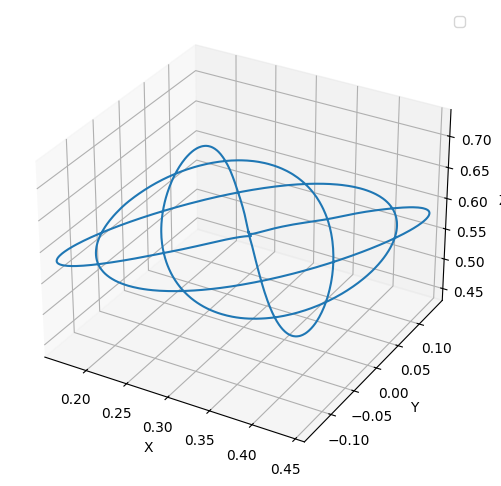

In [4]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot(ee_pose['x'], ee_pose['y'], ee_pose['z'])

x_max = ee_pose['x'].max()
x_min = ee_pose['x'].min()
y_max = ee_pose['y'].max()
y_min = ee_pose['y'].min()
z_max = ee_pose['z'].max()
z_min = ee_pose['z'].min()
max_range = np.array([x_max-x_min, y_max-y_min, z_max-z_min]).max() / 2.0
mid_x = (x_max+x_min) * 0.5
mid_y = (y_max+y_min) * 0.5
mid_z = (z_max+z_min) * 0.5

ax.set_xlim(mid_x - max_range, mid_x + max_range)
ax.set_ylim(mid_y - max_range, mid_y + max_range)
ax.set_zlim(mid_z - max_range, mid_z + max_range)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.legend()
plt.show()

Plot the positions on the XY plane of the end effector and compare it with the ones from the computed trajectory.

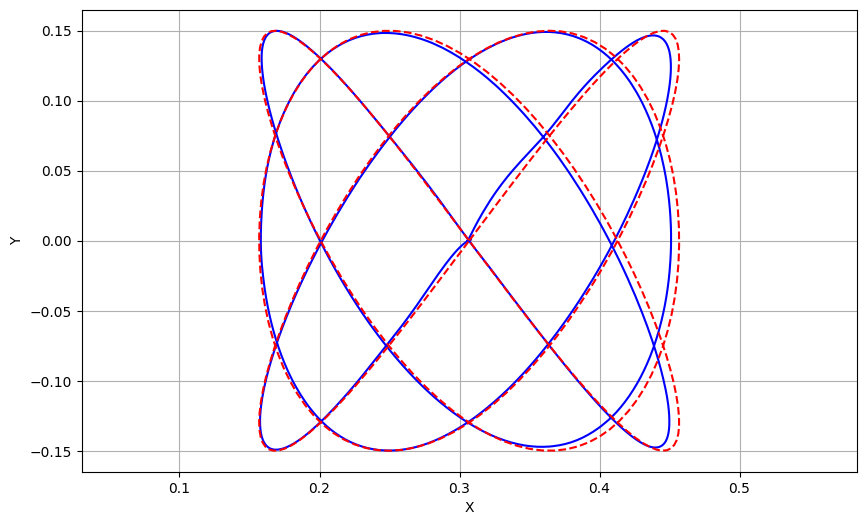

In [5]:
plt.figure(figsize=(10, 6))
plt.plot(ee_pose['x'], ee_pose['y'], label='End-effector points', color='blue')
plt.plot(original_trajectory['x'], original_trajectory['y'], label='Assigned points', color='red', linestyle='--')
plt.xlabel('X')
plt.ylabel('Y')
plt.axis('equal')
plt.grid(True)
plt.show()

Plot the values of $x$, $y$ and $z$.

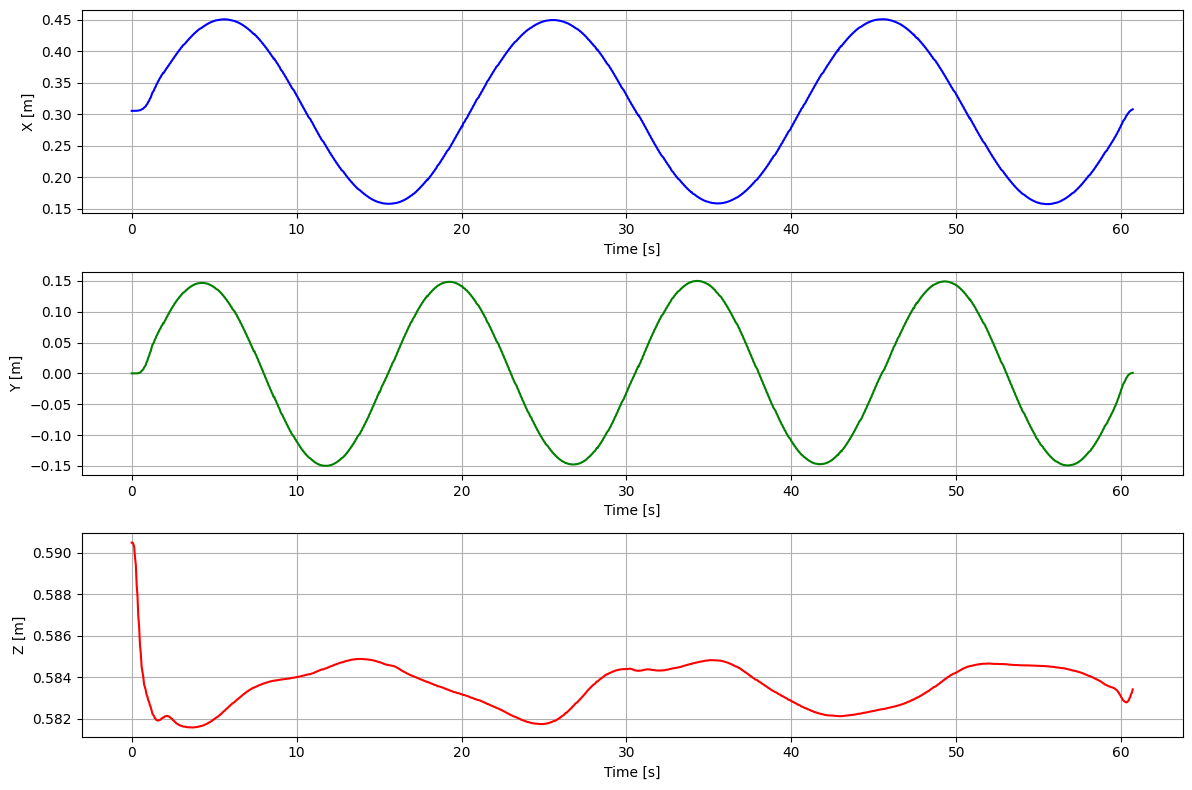

In [6]:
plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(ee_pose['time'], ee_pose['x'], label='x', color='blue')
plt.xlabel('Time [s]')
plt.ylabel('X [m]')
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(ee_pose['time'], ee_pose['y'], label='y', color='green')
plt.xlabel('Time [s]')
plt.ylabel('Y [m]')
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(ee_pose['time'], ee_pose['z'], label='z', color='red')
plt.xlabel('Time [s]')
plt.ylabel('Z [m]')
plt.grid(True)

plt.tight_layout()
plt.show()

Plot the orientation values.

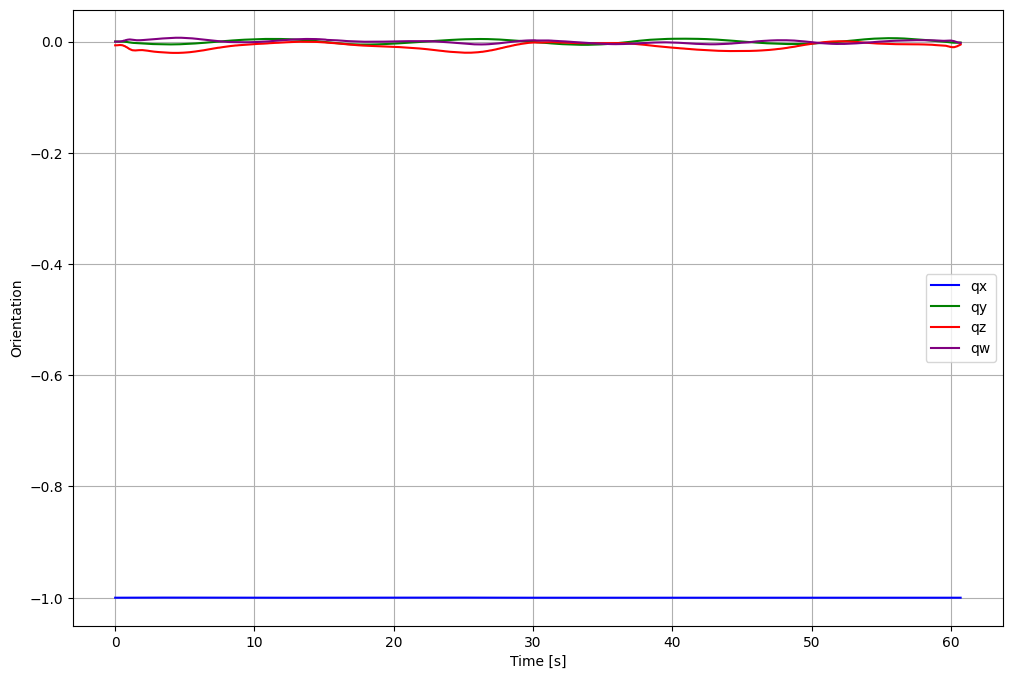

In [7]:
plt.figure(figsize=(12, 8))
plt.plot(ee_pose['time'], ee_pose['qx'], label='qx', color='blue')
plt.plot(ee_pose['time'], ee_pose['qy'], label='qy', color='green')
plt.plot(ee_pose['time'], ee_pose['qz'], label='qz', color='red')
plt.plot(ee_pose['time'], ee_pose['qw'], label='qw', color='purple')
plt.xlabel('Time [s]')
plt.ylabel('Orientation')
plt.legend()
plt.grid(True)
plt.show()

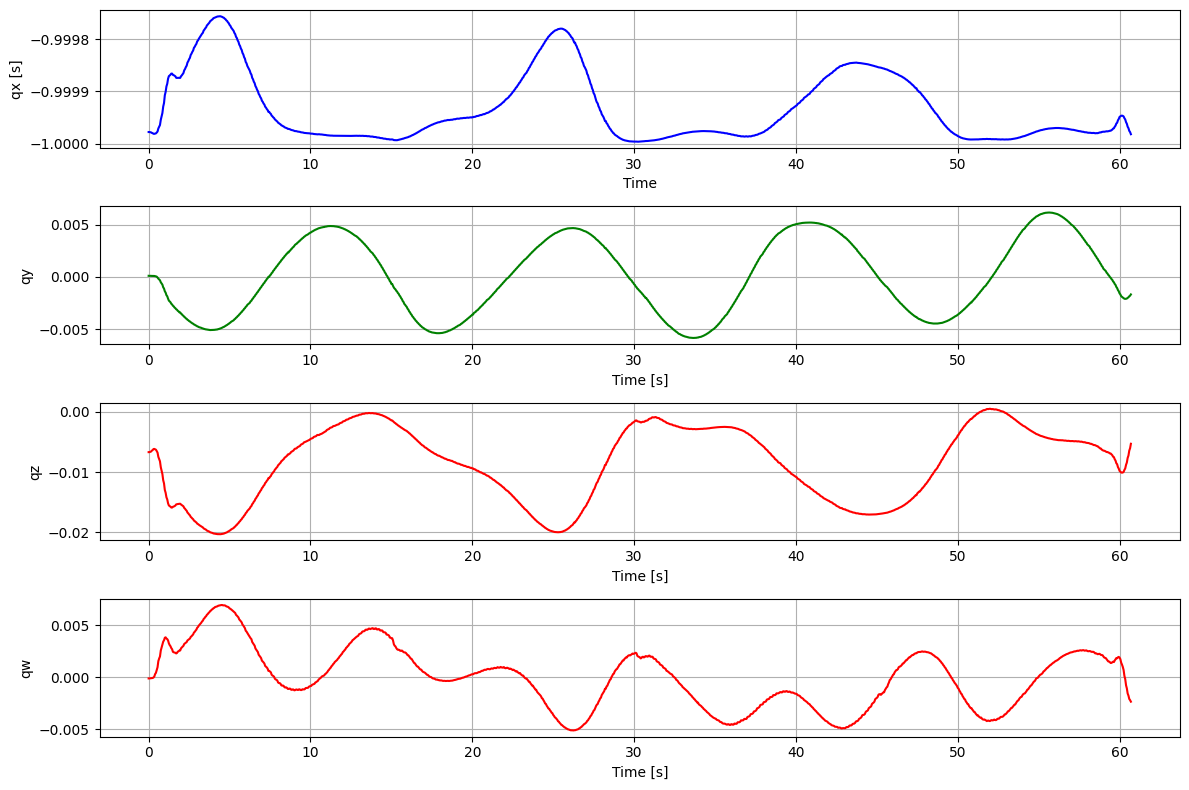

In [8]:
plt.figure(figsize=(12, 8))

plt.subplot(4, 1, 1)
plt.plot(ee_pose['time'], ee_pose['qx'], label='qx', color='blue')
plt.xlabel('Time')
plt.ylabel('qx [s]')
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(ee_pose['time'], ee_pose['qy'], label='qy', color='green')
plt.xlabel('Time [s]')
plt.ylabel('qy')
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(ee_pose['time'], ee_pose['qz'], label='qz', color='red')
plt.xlabel('Time [s]')
plt.ylabel('qz')
plt.grid(True)

plt.subplot(4, 1, 4)
plt.plot(ee_pose['time'], ee_pose['qw'], label='qw', color='red')
plt.xlabel('Time [s]')
plt.ylabel('qw')
plt.grid(True)

plt.tight_layout()
plt.show()

Compute mean and variance for the orientation variables and z.

In [9]:
orientation_mean = ee_pose[['qx', 'qy', 'qz', 'qw', 'z']].mean()
orientation_variance = ee_pose[['qx', 'qy', 'qz', 'qw', 'z']].var()

print("Mean of orientation variables and z:")
print(orientation_mean)
print("\nVariance of orientation variables and z:")
print(orientation_variance)

Mean of orientation variables and z:
qx   -0.999933
qy    0.000064
qz   -0.008599
qw   -0.000035
z     0.583552
dtype: float64

Variance of orientation variables and z:
qx    4.305609e-09
qy    1.326645e-05
qz    3.899300e-05
qw    8.400905e-06
z     1.263270e-06
dtype: float64


Plot the position values of the joints.

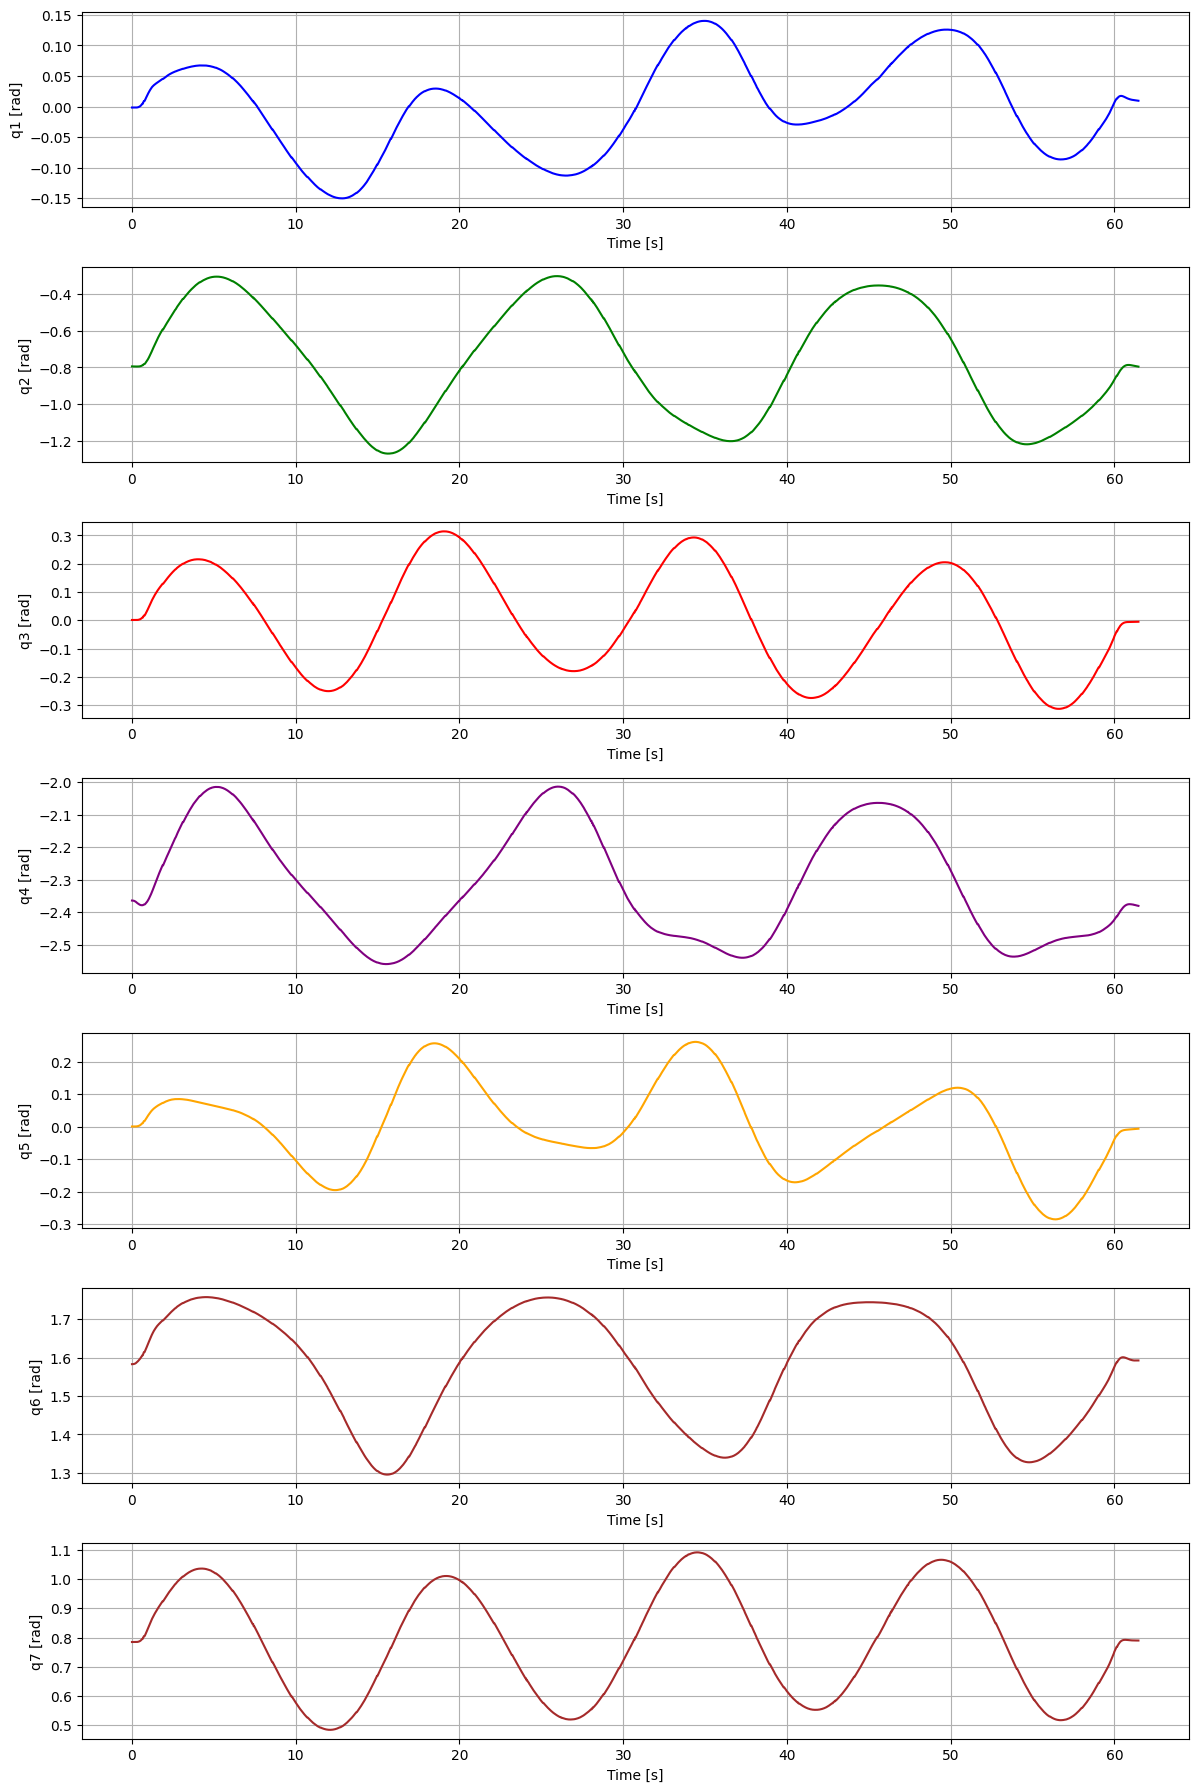

In [10]:
plt.figure(figsize=(12, 18))

plt.subplot(7, 1, 1)
plt.plot(joint_positions['time'], joint_positions['joint1'], label='joint1', color='blue')
plt.xlabel('Time [s]')
plt.ylabel('q1 [rad]')
plt.grid(True)

plt.subplot(7, 1, 2)
plt.plot(joint_positions['time'], joint_positions['joint2'], label='joint2', color='green')
plt.xlabel('Time [s]')
plt.ylabel('q2 [rad]')
plt.grid(True)

plt.subplot(7, 1, 3)
plt.plot(joint_positions['time'], joint_positions['joint3'], label='joint3', color='red')
plt.xlabel('Time [s]')
plt.ylabel('q3 [rad]')
plt.grid(True)

plt.subplot(7, 1, 4)
plt.plot(joint_positions['time'], joint_positions['joint4'], label='joint4', color='purple')
plt.xlabel('Time [s]')
plt.ylabel('q4 [rad]')
plt.grid(True)

plt.subplot(7, 1, 5)
plt.plot(joint_positions['time'], joint_positions['joint5'], label='joint5', color='orange')
plt.xlabel('Time [s]')
plt.ylabel('q5 [rad]')
plt.grid(True)

plt.subplot(7, 1, 6)
plt.plot(joint_positions['time'], joint_positions['joint6'], label='joint6', color='brown')
plt.xlabel('Time [s]')
plt.ylabel('q6 [rad]')
plt.grid(True)

plt.subplot(7, 1, 7)
plt.plot(joint_positions['time'], joint_positions['joint7'], label='joint7', color='brown')
plt.xlabel('Time [s]')
plt.ylabel('q7 [rad]')
plt.grid(True)

plt.tight_layout()
plt.show()

Plot the velocity values of the joints.

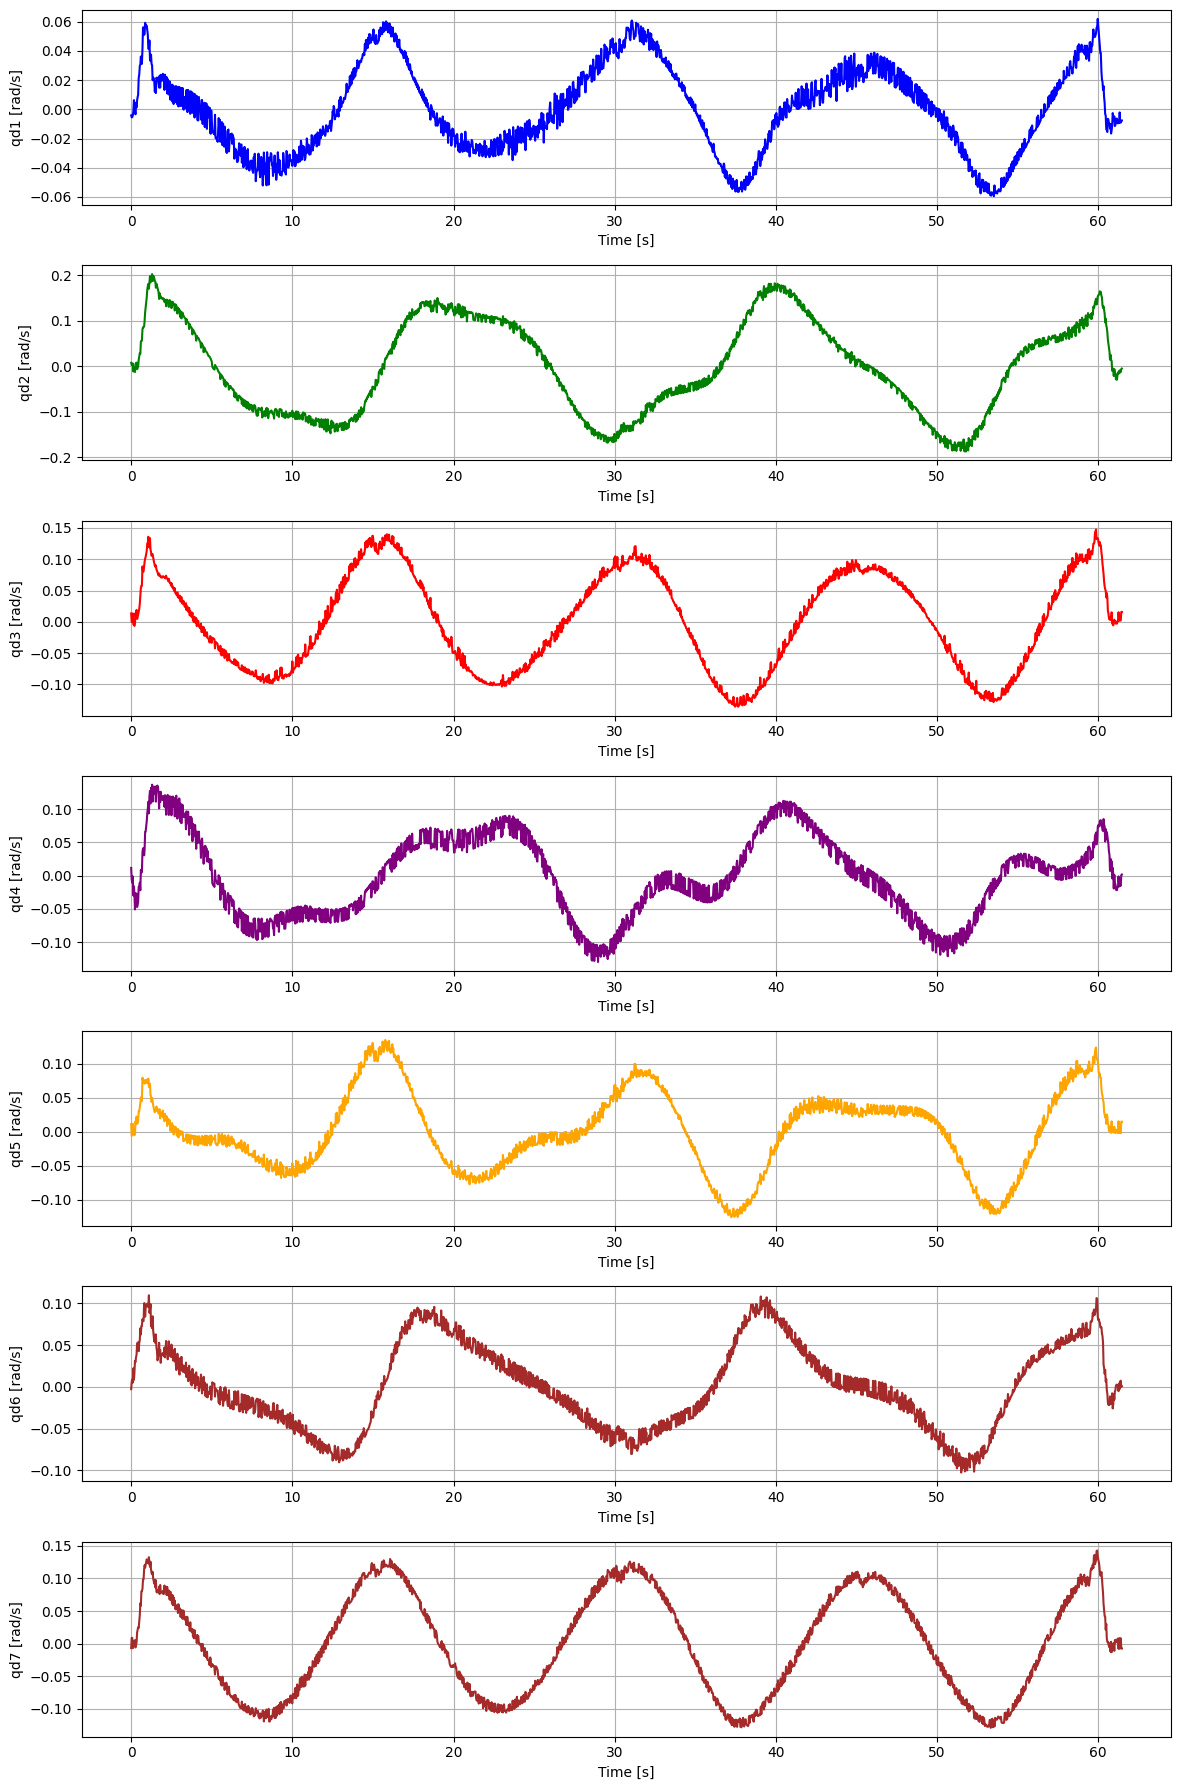

In [11]:
plt.figure(figsize=(12, 18))

plt.subplot(7, 1, 1)
plt.plot(joint_velocities['time'], joint_velocities['joint1'], label='joint1', color='blue')
plt.xlabel('Time [s]')
plt.ylabel('qd1 [rad/s]')
plt.grid(True)

plt.subplot(7, 1, 2)
plt.plot(joint_velocities['time'], joint_velocities['joint2'], label='joint2', color='green')
plt.xlabel('Time [s]')
plt.ylabel('qd2 [rad/s]')
plt.grid(True)

plt.subplot(7, 1, 3)
plt.plot(joint_velocities['time'], joint_velocities['joint3'], label='joint3', color='red')
plt.xlabel('Time [s]')
plt.ylabel('qd3 [rad/s]')
plt.grid(True)

plt.subplot(7, 1, 4)
plt.plot(joint_velocities['time'], joint_velocities['joint4'], label='joint4', color='purple')
plt.xlabel('Time [s]')
plt.ylabel('qd4 [rad/s]')
plt.grid(True)

plt.subplot(7, 1, 5)
plt.plot(joint_velocities['time'], joint_velocities['joint5'], label='joint5', color='orange')
plt.xlabel('Time [s]')
plt.ylabel('qd5 [rad/s]')
plt.grid(True)

plt.subplot(7, 1, 6)
plt.plot(joint_velocities['time'], joint_velocities['joint6'], label='joint6', color='brown')
plt.xlabel('Time [s]')
plt.ylabel('qd6 [rad/s]')
plt.grid(True)

plt.subplot(7, 1, 7)
plt.plot(joint_velocities['time'], joint_velocities['joint7'], label='joint7', color='brown')
plt.xlabel('Time [s]')
plt.ylabel('qd7 [rad/s]')
plt.grid(True)

plt.tight_layout()
plt.show()